# **Model Build**

In [ ]:
# =============================================================================
# WHY TENSORFLOW + KERAS?
# -----------------------------------------------------------------------------
# TensorFlow (TF) is Google's open-source deep learning framework. It provides:
#   - Low-level tensor math (like NumPy, but on GPU/TPU and with autograd).
#   - A graph execution engine (eager mode by default, graph mode for speed).
#   - Deployment tooling (TF Serving, TF Lite for mobile, TF.js for browsers).
#
# Keras is a HIGH-LEVEL API that sits on top of TensorFlow (since TF 2.0,
# Keras is bundled inside TF as `tf.keras`). It abstracts away the tedious
# parts of building neural networks:
#   - Layer definitions (Conv2D, Dense, etc.) as reusable objects.
#   - Automatic shape inference as you chain layers.
#   - A clean Functional API — `layer(inputs)` — that returns a symbolic
#     tensor, making multi-input / multi-output models trivial to describe.
#   - Built-in training loops (`model.fit`) and callbacks.
#
# We use Keras here because the code reads like the math: each layer is a
# function applied to the previous tensor. Without Keras, you'd have to
# manually create variables, manage shapes, and write the forward pass.
#
# -----------------------------------------------------------------------------
# WHAT DOES PYTORCH DO DIFFERENTLY?
# -----------------------------------------------------------------------------
# PyTorch (Meta) is the other major framework. Key differences:
#   - EAGER-FIRST design: it feels like plain Python/NumPy. Models are Python
#     classes that inherit from `nn.Module`, and the forward pass is defined
#     in a `forward(self, x)` method.
#   - DYNAMIC graphs by default (both frameworks are now eager, but PyTorch's
#     graph-building intuition remains more "define-by-run").
#   - Same model in PyTorch would look like:
#
#         import torch.nn as nn
#         class Net(nn.Module):
#             def __init__(self):
#                 super().__init__()
#                 self.conv1 = nn.Conv2d(3, 32, 3)
#                 self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
#                 self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
#                 self.pool  = nn.MaxPool2d(2, 2)
#                 self.fc1   = nn.Linear(7*7*128, 128)
#             def forward(self, x):
#                 x = self.pool(nn.functional.relu(self.conv1(x)))
#                 x = self.pool(nn.functional.relu(self.conv2(x)))
#                 x = self.pool(nn.functional.relu(self.conv3(x)))
#                 x = x.flatten(1)
#                 x = nn.functional.relu(self.fc1(x))
#                 return x
#
#   - PyTorch is generally preferred in RESEARCH (easier debugging, Pythonic).
#   - TensorFlow/Keras is often preferred in PRODUCTION (mature deployment stack).
#   - The underlying math is identical — cross-correlation, ReLU, pooling, etc.
# =============================================================================


# -----------------------------------------------------------------------------
# IMPORTS
# -----------------------------------------------------------------------------
# `Input`, `Model`  — from the Keras Functional API. `Input` declares the
#                     expected shape of a single sample. `Model` wraps the
#                     input and output tensors into a trainable object.
# `Conv2D`          — 2D convolution layer (actually cross-correlation,
#                     as is standard in all DL frameworks; see earlier demo).
# `MaxPooling2D`    — downsampling layer that takes the max over 2×2 windows.
# `Flatten`         — reshapes the 3D feature maps (H, W, C) into a 1D vector.
# `Dense`           — fully-connected layer (matrix multiply + bias + activation).
# -----------------------------------------------------------------------------
from tensorflow.keras import Input, Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense


# -----------------------------------------------------------------------------
# INPUT LAYER
# -----------------------------------------------------------------------------
# `Input(shape=(64, 64, 3))` declares that each sample is a 64×64 RGB image.
# - The batch dimension is deliberately OMITTED — Keras adds it automatically.
# - Internally, the symbolic tensor has shape (None, 64, 64, 3), where None
#   means "any batch size." This lets you train and predict with different
#   batch sizes on the same model.
# - `inputs` is NOT real data — it's a placeholder used to trace the graph.
# -----------------------------------------------------------------------------
inputs = Input(shape=(64, 64, 3))


# -----------------------------------------------------------------------------
# BLOCK 1 — Conv → ReLU → MaxPool
# -----------------------------------------------------------------------------
# `Conv2D(32, (3, 3), activation='relu')`
#   - 32 filters, each 3×3. Each filter produces one output feature map, so
#     the output has 32 channels.
#   - `activation='relu'` applies ReLU (max(0, x)) right after the conv,
#     fusing the two ops into one layer (faster, less memory).
#   - `padding` defaults to 'valid' → no zero-padding → 3×3 kernel shrinks
#     each spatial dim by 2: 64 → 62.
#   - `strides` defaults to (1, 1) → the kernel slides one pixel at a time.
#   - Learnable params: 32 filters × (3×3×3 weights + 1 bias) = 32 × 28 = 896.
#
# `(inputs)` at the end calls the layer on the previous tensor — this is the
# Keras Functional API style. It returns a NEW symbolic tensor of shape
# (None, 62, 62, 32). Nothing is computed yet; we're just building a graph.
#
# `MaxPooling2D((2, 2))`
#   - Takes the maximum value over each non-overlapping 2×2 window.
#   - Halves each spatial dimension: 62 → 31. Channels stay at 32.
#   - Has NO learnable parameters — it's a fixed operation.
#   - Purpose: (a) reduce compute, (b) enlarge the receptive field of deeper
#     layers, (c) provide small translation invariance.
# -----------------------------------------------------------------------------
x = Conv2D(32, (3, 3), activation='relu')(inputs)
x = MaxPooling2D((2, 2))(x)


# -----------------------------------------------------------------------------
# BLOCK 2 — Conv → ReLU → MaxPool (with `padding='same'`)
# -----------------------------------------------------------------------------
# `Conv2D(64, (3, 3), activation='relu', padding='same')`
#   - Doubles the number of filters (32 → 64). It's standard practice to
#     grow channels as spatial size shrinks, keeping total compute balanced.
#   - `padding='same'` pads the input with zeros so the OUTPUT spatial size
#     equals the input: 31 → 31. Formula: out = ceil(in / stride).
#   - Learnable params: 64 × (3×3×32 + 1) = 64 × 289 = 18,496.
#
# `MaxPooling2D((2, 2))`
#   - Halves spatial dims again: 31 → 15 (floor division).
#   - Output tensor: (None, 15, 15, 64).
# -----------------------------------------------------------------------------
x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = MaxPooling2D((2, 2))(x)


# -----------------------------------------------------------------------------
# BLOCK 3 — Conv → ReLU → MaxPool (deepest block)
# -----------------------------------------------------------------------------
# `Conv2D(128, (3, 3), activation='relu', padding='same')`
#   - 128 filters → richer, more abstract features (edges → parts → objects).
#   - Same padding preserves 15×15.
#   - Learnable params: 128 × (3×3×64 + 1) = 128 × 577 = 73,856.
#
# `MaxPooling2D((2, 2))`
#   - Halves spatial dims: 15 → 7.
#   - Output tensor: (None, 7, 7, 128).
#   - These 7×7×128 = 6,272 values form the "deep feature vector" for the image.
# -----------------------------------------------------------------------------
x = Conv2D(128, (3, 3), activation='relu', padding='same')(x)
x = MaxPooling2D((2, 2))(x)


# -----------------------------------------------------------------------------
# FLATTEN — turn 3D feature maps into a 1D vector
# -----------------------------------------------------------------------------
# `Flatten()` unravels (7, 7, 128) → (6272,). This makes the tensor digestible
# by `Dense` layers, which only accept 1D feature vectors.
#
# Note: Flatten introduces NO parameters and NO computation — just a reshape.
# This is where spatial structure is discarded; the classifier loses the
# notion of "where" a feature was, only "whether" it appeared.
# (Modern architectures often use GlobalAveragePooling2D here instead, which
#  averages each channel to a single number → far fewer parameters.)
# -----------------------------------------------------------------------------
x = Flatten()(x)


# -----------------------------------------------------------------------------
# DENSE HIDDEN LAYER — fully connected, 128 units
# -----------------------------------------------------------------------------
# `Dense(128, activation='relu')`
#   - Each of the 128 neurons is connected to ALL 6,272 inputs.
#   - Params: 6272 × 128 weights + 128 biases = 802,944 — this single layer
#     dominates the parameter count!
#   - ReLU introduces non-linearity so the network can learn complex mappings.
#   - This is the "representation bottleneck" where the network learns
#     high-level combinations of the conv features (e.g., "digit-like shape").
#
# Note: The slide stops here because it's demonstrating the feature-extractor
# trunk. To make a complete classifier, add an output layer:
#
#     outputs = Dense(10, activation='softmax')(x)   # 10 classes
#     model   = Model(inputs, outputs)
#
# For BINARY classification, use `Dense(1, activation='sigmoid')` instead.
# -----------------------------------------------------------------------------
x = Dense(128, activation='relu')(x)


# -----------------------------------------------------------------------------
# BUILD THE MODEL
# -----------------------------------------------------------------------------
# Wrapping `inputs` and `outputs` into a `Model` creates a trainable Keras
# object. At this point Keras:
#   - Verifies the graph is fully connected.
#   - Collects all layers and their trainable weights.
#   - Computes parameter counts and produces `model.summary()`.
#
# `model.compile(...)` is needed BEFORE training:
#     model.compile(optimizer='adam',
#                   loss='sparse_categorical_crossentropy',
#                   metrics=['accuracy'])
#
# Then train with:
#     model.fit(train_images, train_labels,
#               epochs=10, batch_size=32,
#               validation_split=0.1)
#
# This is precisely what Keras saves you from: PyTorch would require you to
# write the training loop by hand (zero_grad → forward → loss → backward →
# step, for every batch, every epoch).
# -----------------------------------------------------------------------------
outputs = Dense(10, activation='softmax')(x)   # ← added for completeness
model = Model(inputs=inputs, outputs=outputs)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 31, 31, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 15, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 15, 15, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 897,482 (3.42 MB)

 Trainable params: 897,482 (3.42 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
inputs = Input(shape=(64, 64, 3))

x = Conv2D(32, (3, 3), activation='relu')(inputs)
x = MaxPooling2D((2, 2))(x)

x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = MaxPooling2D((2, 2))(x)

x = Conv2D(128, (3, 3), activation='relu', padding='same')(x)
x = MaxPooling2D((2, 2))(x)

x = Flatten()(x)
x = Dense(128, activation='relu')(x)
outputs = Dense(10, activation='softmax')(x)   # ← added for completeness
model = Model(inputs=inputs, outputs=outputs)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 31, 31, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 15, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 15, 15, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 897,482 (3.42 MB)

 Trainable params: 897,482 (3.42 MB)

 Non-trainable params: 0 (0.00 B)

Input shape: (1, 64, 64, 3)


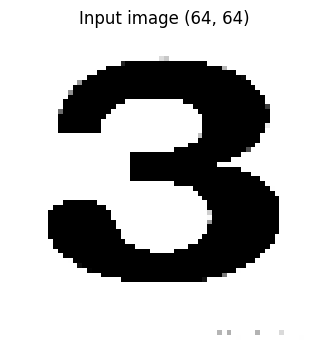

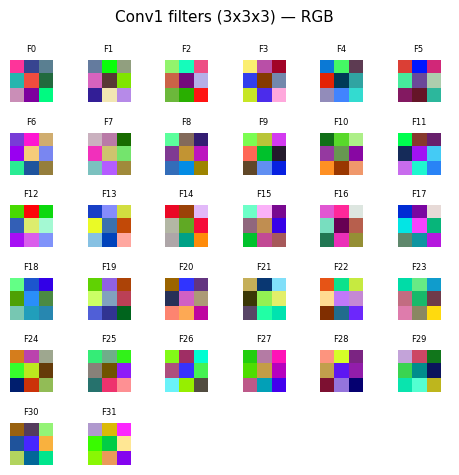

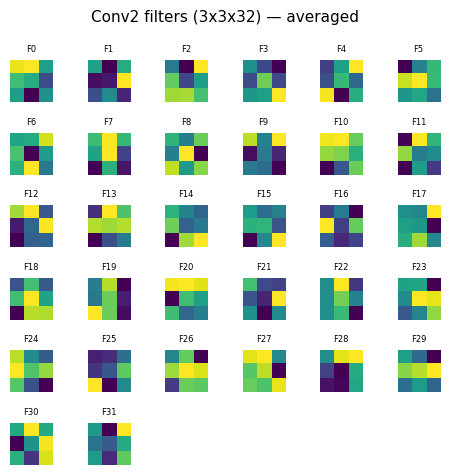

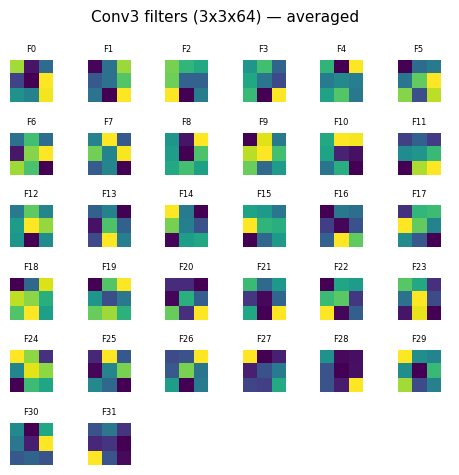

Model: "basic_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 31, 31, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 15, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 15, 15, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 897,482 (3.42 MB)

 Trainable params: 897,482 (3.42 MB)

 Non-trainable params: 0 (0.00 B)


Prediction vector (untrained): [[4.0093530e-15 2.4647332e-24 3.2871259e-38 1.0000000e+00 9.9254800e-37
  1.6151270e-12 0.0000000e+00 3.5522249e-23 7.1655849e-19 9.7425757e-28]]
Predicted class: 3


In [ ]:
# Basic CNN demo: input image → filters visualization → model summary

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import Input, Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.preprocessing import image

# --- Config ---
IMG_PATH = "sample.png"     # change to your image path
IMG_SIZE = (64, 64)         # must match Input shape
NUM_CLASSES = 10            # e.g. 10 for MNIST, 1 for binary

# --- Load and preprocess image ---
img_pil = image.load_img(IMG_PATH, target_size=IMG_SIZE)   # resize
img_arr = image.img_to_array(img_pil)                       # to numpy
img_display = img_arr.astype("uint8")                       # for display
img_input = np.expand_dims(img_arr, axis=0)                 # add batch dim

print("Input shape:", img_input.shape)

# --- Build a basic CNN ---
inputs = Input(shape=(*IMG_SIZE, 3))

x = Conv2D(32,  (3, 3), activation='relu', name='conv1')(inputs)   # 32 filters, 3x3
x = MaxPooling2D((2, 2))(x)                                        # halve spatial size

x = Conv2D(64,  (3, 3), activation='relu', padding='same', name='conv2')(x)  # 64 filters
x = MaxPooling2D((2, 2))(x)

x = Conv2D(128, (3, 3), activation='relu', padding='same', name='conv3')(x)  # 128 filters
x = MaxPooling2D((2, 2))(x)

x = Flatten()(x)                                                   # 3D → 1D
x = Dense(128, activation='relu', name='fc1')(x)                   # hidden layer
outputs = Dense(NUM_CLASSES, activation='softmax', name='predictions')(x)  # output layer

model = Model(inputs=inputs, outputs=outputs, name="basic_cnn")

# --- Show input image ---
plt.figure(figsize=(4, 4))
plt.imshow(img_display)
plt.title(f"Input image {IMG_SIZE}")
plt.axis("off")
plt.show()

# --- Visualize filters of each conv layer ---
def plot_filters(layer, max_filters=32, title=None):
    W = layer.get_weights()[0]                  # shape: (kh, kw, in_ch, out_ch)
    kh, kw, in_ch, out_ch = W.shape
    n_show = min(out_ch, max_filters)           # cap number shown

    grid = int(np.ceil(np.sqrt(n_show)))
    fig, axes = plt.subplots(grid, grid, figsize=(grid * 0.8, grid * 0.8))

    for i, ax in enumerate(axes.flat):
        if i >= n_show:
            ax.axis("off")
            continue

        filt = W[:, :, :, i]                    # one filter

        if in_ch == 3:                          # first-layer → RGB
            f = filt - filt.min()
            f = f / (f.max() + 1e-8)
            ax.imshow(f)
        else:                                   # deeper layers → grayscale
            ax.imshow(filt.mean(axis=-1), cmap="viridis")

        ax.set_title(f"F{i}", fontsize=6)
        ax.axis("off")

    fig.suptitle(title or f"Filters — {layer.name} ({out_ch} total)", fontsize=11)
    plt.tight_layout()
    plt.show()

plot_filters(model.get_layer("conv1"), 32, "Conv1 filters (3x3x3) — RGB")
plot_filters(model.get_layer("conv2"), 32, "Conv2 filters (3x3x32) — averaged")
plot_filters(model.get_layer("conv3"), 32, "Conv3 filters (3x3x64) — averaged")

# --- Model summary ---
model.summary()

# --- Forward pass with the input image ---
preds = model.predict(img_input, verbose=0)
print("\nPrediction vector (untrained):", preds)
print("Predicted class:", int(np.argmax(preds[0])))

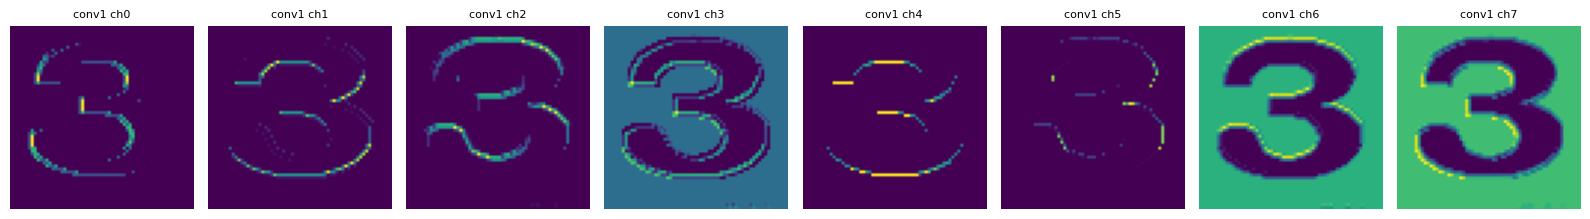

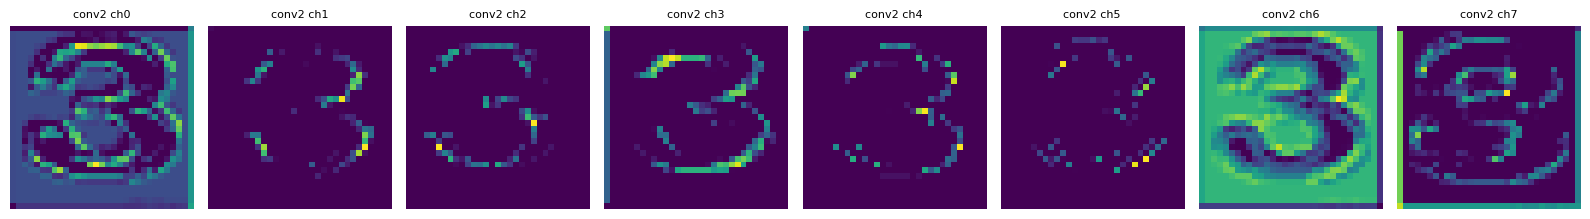

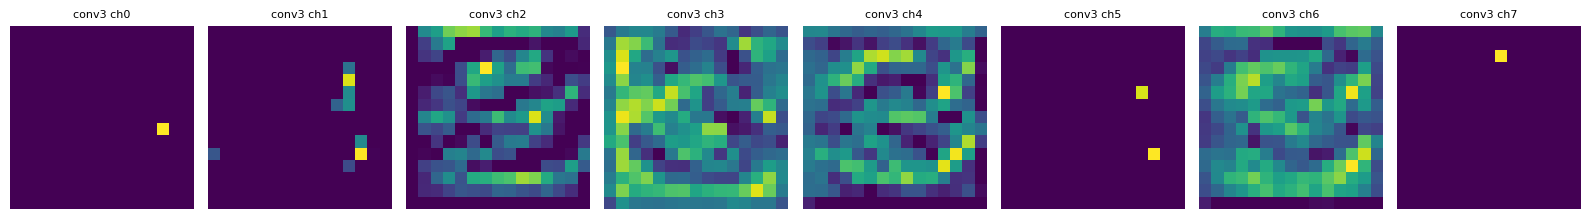

In [ ]:
activation_model = Model(
    inputs=model.inputs,
    outputs=[model.get_layer(n).output for n in ["conv1", "conv2", "conv3"]],
)
acts = activation_model.predict(img_input, verbose=0)

for name, act in zip(["conv1", "conv2", "conv3"], acts):
    fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
    for i, ax in enumerate(axes):
        ax.imshow(act[0, :, :, i], cmap="viridis")   # first 8 channels
        ax.set_title(f"{name} ch{i}", fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()